In [15]:
import numpy as np
import pandas as pd
import geopandas as gpd
import rasterio as rio
import matplotlib as mpl
from matplotlib import pyplot as plt
from cartopy import feature as cf
from cartopy import crs as ccrs
from matplotlib.colors import BoundaryNorm 
from cmocean import plots, cm

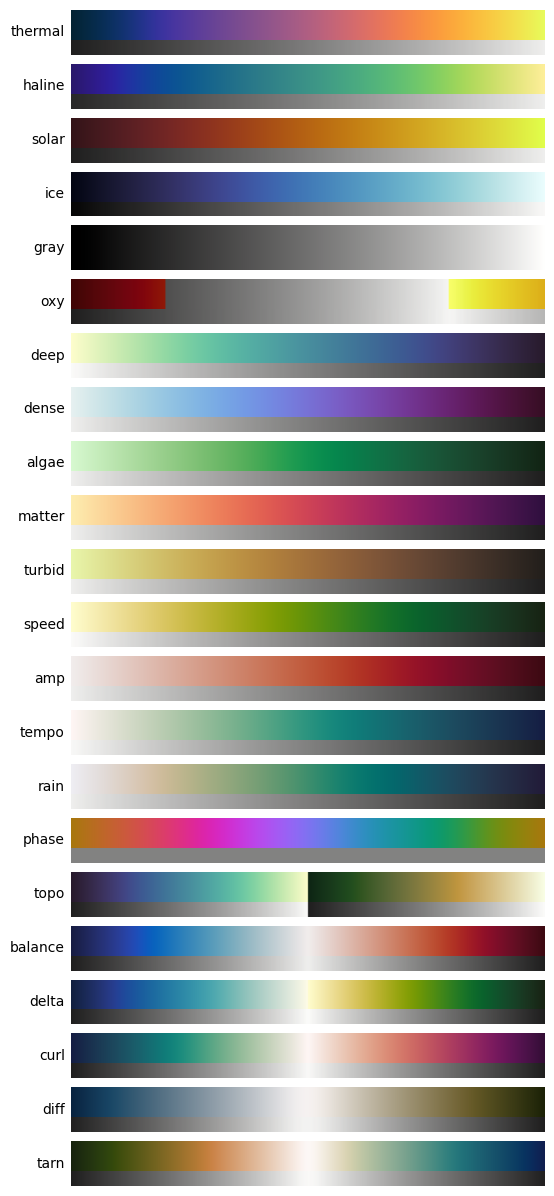

In [7]:
plots.plot_gallery()

In [9]:
world_map = gpd.read_file(r"../data/gadm-world/world-map.shp")
world_map = world_map.drop([31])
world_map_eck4 = world_map.to_crs('ESRI:54012')

In [13]:
src = rio.open('../results/area-of-habitat/species-richness-vertebrates-1km.tif')

In [14]:
species_richness_vertebrates = src.read(1)

In [17]:
country_raster_1km_ = rio.open(r"D:\wty\Dropbox\code\country_raster\results\country_raster_eck4_1km.tif")

In [23]:
country_raster_1km = country_raster_1km_.read(1)

In [20]:
np.max(species_richness_vertebrates)

np.uint16(881)

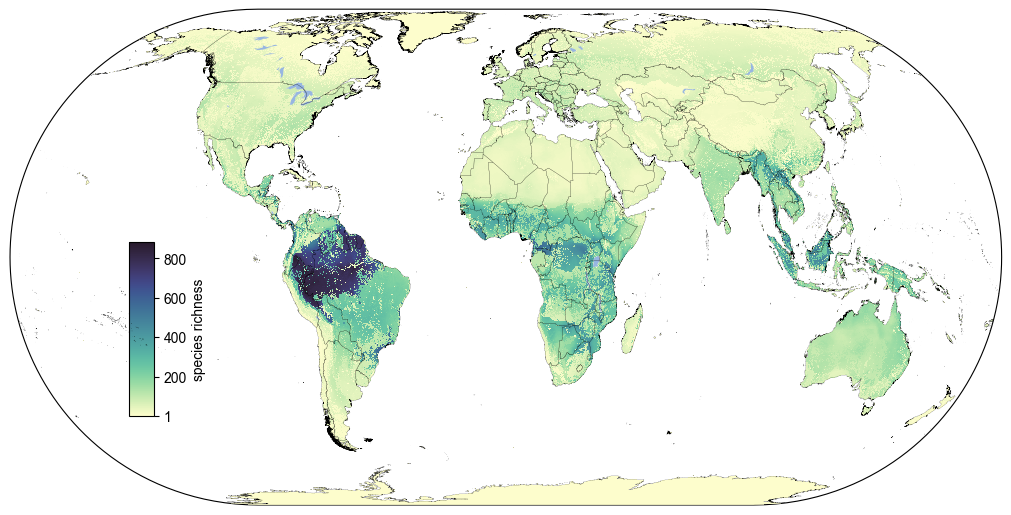

In [34]:
fig = plt.figure(figsize=(10, 8), constrained_layout=True)
plt.rcParams['font.family'] = 'Arial' 

ax1 = plt.subplot(1, 1, 1, projection=ccrs.EckertIV())
ax1.add_feature(cf.LAKES, zorder=6)
world_map_eck4.plot(color='none', edgecolor='k', lw=0.1, ax=ax1, zorder=10)
display_extent_1km = [country_raster_1km_.bounds.left, country_raster_1km_.bounds.right, country_raster_1km_.bounds.bottom, country_raster_1km_.bounds.top]
im1 = ax1.imshow(np.where(country_raster_1km > 0, species_richness_vertebrates, np.nan), vmin=1, vmax=881, cmap=cm.deep, interpolation='nearest', origin='upper', extent=display_extent_1km, zorder=4)

cax1 = ax1.inset_axes([0.12, 0.18, 0.025, 0.35]) 
cbar1 = fig.colorbar(im1, cax=cax1, orientation='vertical', label='species richness')
cbar1.set_ticks([1, 200, 400, 600, 800]) 

plt.show()

In [35]:
fig.savefig('../figures/species-richness-vertebrates.jpg', dpi=600, bbox_inches='tight')